# Exploring category activity and observation coverage

> **Historical v1 analysis.** The modelling target in this workflow ends in September 2025; newer supplemental observations remain separate here. For the current 519-game forecast, see [Notebook 20](20_fixed_cohort_2027_forecast.ipynb). [Notebook 17](17_fixed_sources_integration.ipynb) begins the separate v2 workflow.

![04 / Exploratory Analysis — Activity trends, concentration and observation coverage](assets/pixel_theme/04_exploratory_analysis.svg)

Action has the largest recorded category total in September 2025, while Massively Multiplayer has the highest concentration among its five largest apps at **70.15%**. Comparing September 2024 and 2025 shows Action up **3.61%**, with declines in the other four labels within the prepared sample.

Those totals are read alongside app counts and coverage, because the observed catalog changes over time and internal gaps remain present. This notebook examines those relationships before a modelling dataset is selected.


## Context and scope

The analysis uses database/steam.sqlite built from the pinned snapshots in data/raw/sources.json, with the cohort and missing-observation rules established in Notebooks 02 and 03. Activity is the sum of observed monthly average concurrent players attributed to each category.

The five labels overlap, and later-snapshot metadata is applied retrospectively. Results describe eligible tracked apps through September 2025, with historical sample changes and source omissions limiting broader market interpretation. The year-over-year comparison uses September in both years, avoiding a partial-year comparison; it remains a two-month cross-section.

Calculations and plotting helpers are in [explore_data.py](../src/explore_data.py), while the app-level query is in [category_app_month.sql](../sql/category_app_month.sql). Missing activity remains unknown, and concentration is calculated only from recorded activity in each category/month.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "database/steam.sqlite").exists(), "Run src/prepare_data.py first"
sys.path.insert(0, str(ROOT / "src"))
from notebook_display import configure_notebook, present
configure_notebook()

from explore_data import (
    load_analysis, save_tables, plot_activity, plot_coverage,
    plot_concentration, plot_bridge,
)

figure_folder = ROOT / "outputs/figures"
figure_folder.mkdir(parents=True, exist_ok=True)
monthly, ranked_apps, latest_summary, bridge, bridge_apps = load_analysis()
save_tables(monthly, ranked_apps, latest_summary, bridge, bridge_apps)
print(f"{len(monthly):,} category/month rows; "
      f"{monthly['month'].min():%B %Y} to {monthly['month'].max():%B %Y}.")
print("App-level totals and counts reconcile with the prepared SQL view.")


795 category/month rows; July 2012 to September 2025.
App-level totals and counts reconcile with the prepared SQL view.


## 1. Read the activity trajectories

The shared vertical scale makes category size comparable, with monthly observations retained at their original resolution. Sudden movements provide inspection points rather than evidence of a release, event, or change in player preferences without additional sources.


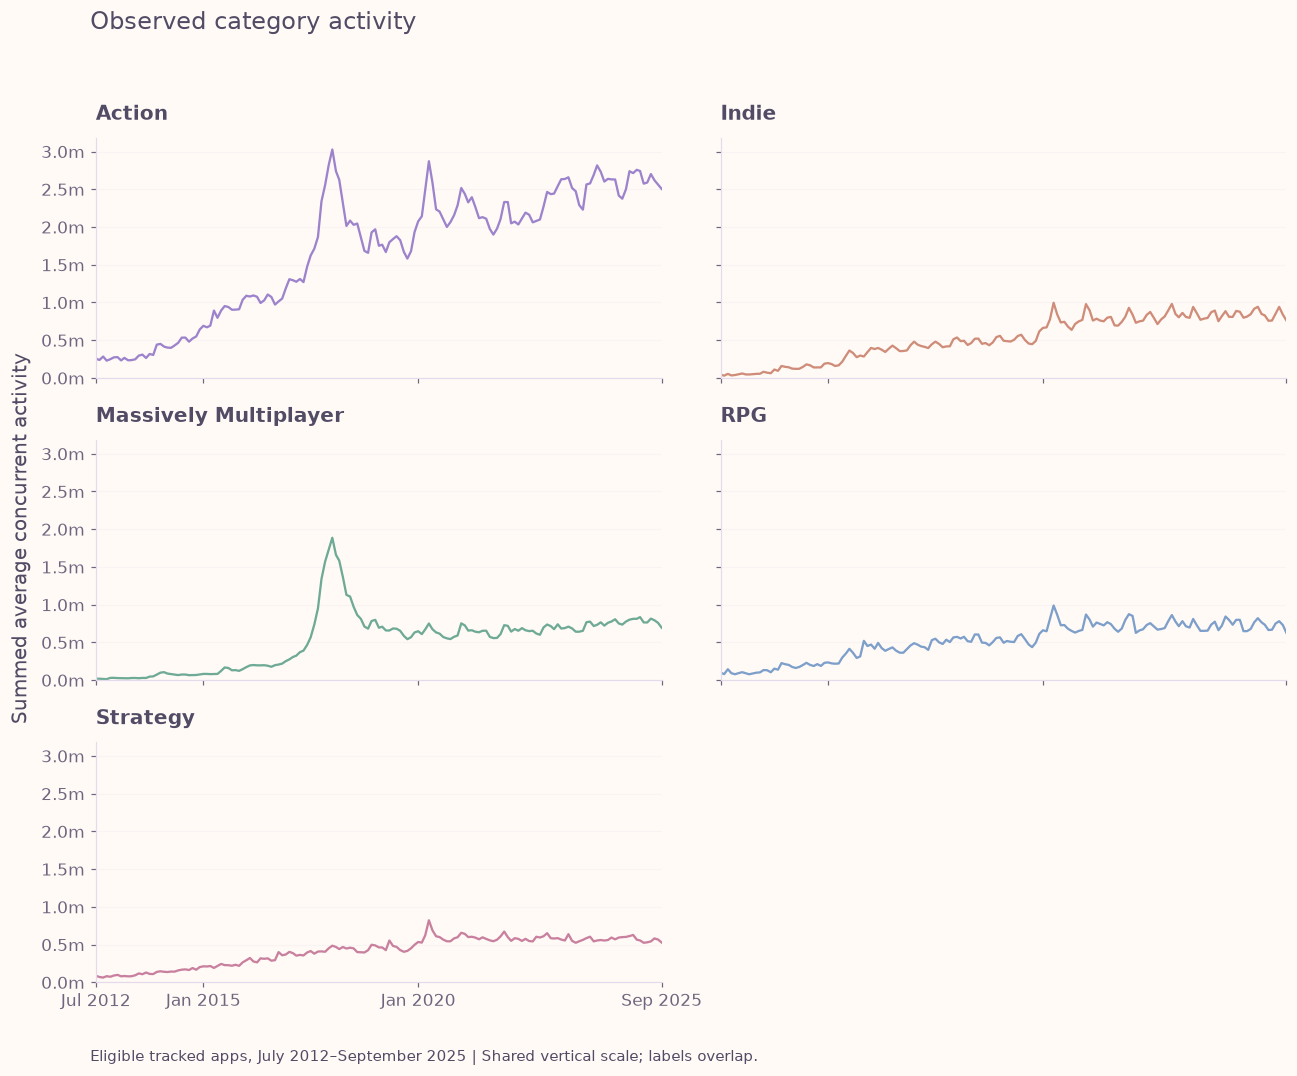

In [2]:
figure = plot_activity(monthly)
figure.savefig(figure_folder / "category_activity.png", dpi=150, bbox_inches="tight")
figure


Action remains the largest label at the latest cutoff, although the category totals contain overlapping games and reflect the source's changing sample. The exact latest values and same-month comparison below provide a bounded view of recent movement.


In [3]:
latest_view = latest_summary[[
    "category", "avg_players", "comparison_activity", "year_over_year_pct",
    "observed_apps", "comparison_observed_apps",
]].rename(columns={
    "category": "Category", "avg_players": "Sep 2025 activity",
    "comparison_activity": "Sep 2024 activity",
    "year_over_year_pct": "Change percent",
    "observed_apps": "Sep 2025 observed apps",
    "comparison_observed_apps": "Sep 2024 observed apps",
})
present(latest_view.round(2), 'Read the activity trajectories')


Category,Sep 2025 activity,Sep 2024 activity,Change percent,Sep 2025 observed apps,Sep 2024 observed apps
Action,"2,503,728.38","2,416,505.27",3.61%,"1,606","1,652"
Indie,"760,753.82","798,104.94",-4.68%,"1,621","1,703"
Massively Multiplayer,"693,909.44","750,757.70",-7.57%,236,229
RPG,"625,704.13","649,198.37",-3.62%,857,904
Strategy,"526,923.53","593,800.47",-11.26%,"1,096","1,133"


## 2. Identify concentration within categories

Top-five share divides the activity of the five largest observed apps by all observed eligible activity in the same category/month. A high share shows that a few games carry much of the category total, which makes their trajectories important to later interpretation.


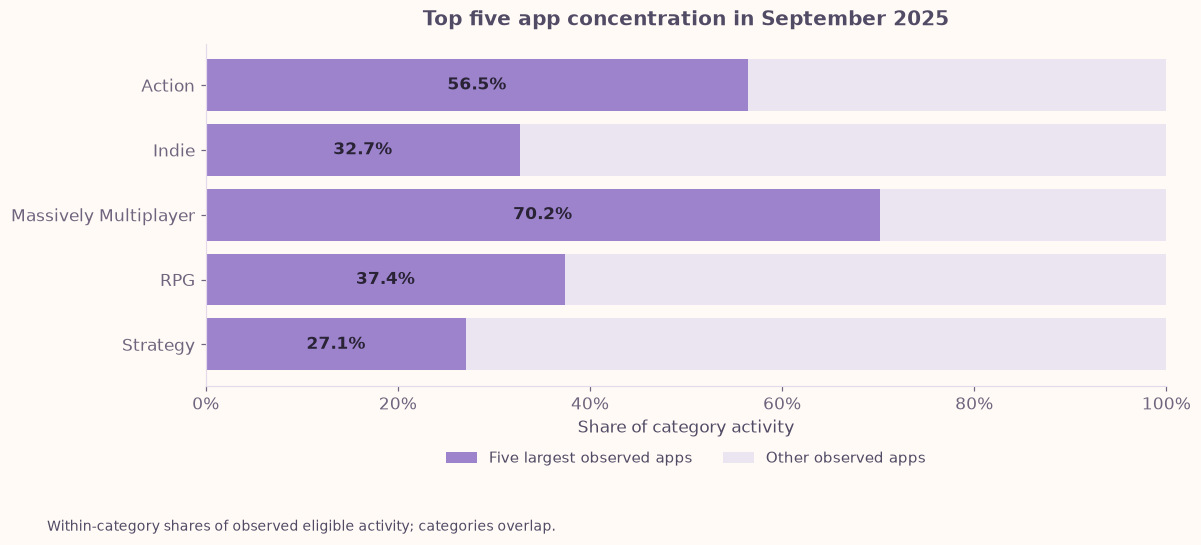

In [4]:
figure = plot_concentration(latest_summary)
figure.savefig(figure_folder / "category_concentration.png", dpi=150, bbox_inches="tight")
figure


In [5]:
latest_month = monthly["month"].max()
leaders = ranked_apps.loc[
    ranked_apps["month"].eq(latest_month) & ranked_apps["rank"].eq(1),
    ["category", "name", "avg_players"],
].merge(latest_summary[["category", "top1_share", "top5_share"]],
        on="category", validate="one_to_one")
leaders["top1_share"] *= 100
leaders["top5_share"] *= 100
present(leaders.rename(columns={
    "category": "Category", "name": "Largest observed app",
    "avg_players": "App activity", "top1_share": "Largest app share percent",
    "top5_share": "Top five share percent",
}).round(2), 'Identify concentration within categories')


Massively Multiplayer has a top-five share of **70.15%**, compared with **56.46%** for Action and **27.12%** for Strategy. Counter-Strike 2 contributes **36.98%** of observed Action activity at this cutoff, so category-level interpretation benefits from checking individual games.

The source assigns Rust to several selected labels, illustrating why the same app can appear in multiple leader rows. These assignments are retained from the metadata, with full top-five records exported for inspection.


## 3. Compare app counts with internal coverage

App counts show how many eligible games contribute in each month, while coverage compares that count with apps whose own first-to-last recorded spans include the month. These views distinguish sample size from internal completeness, with both needed when reading activity trends.


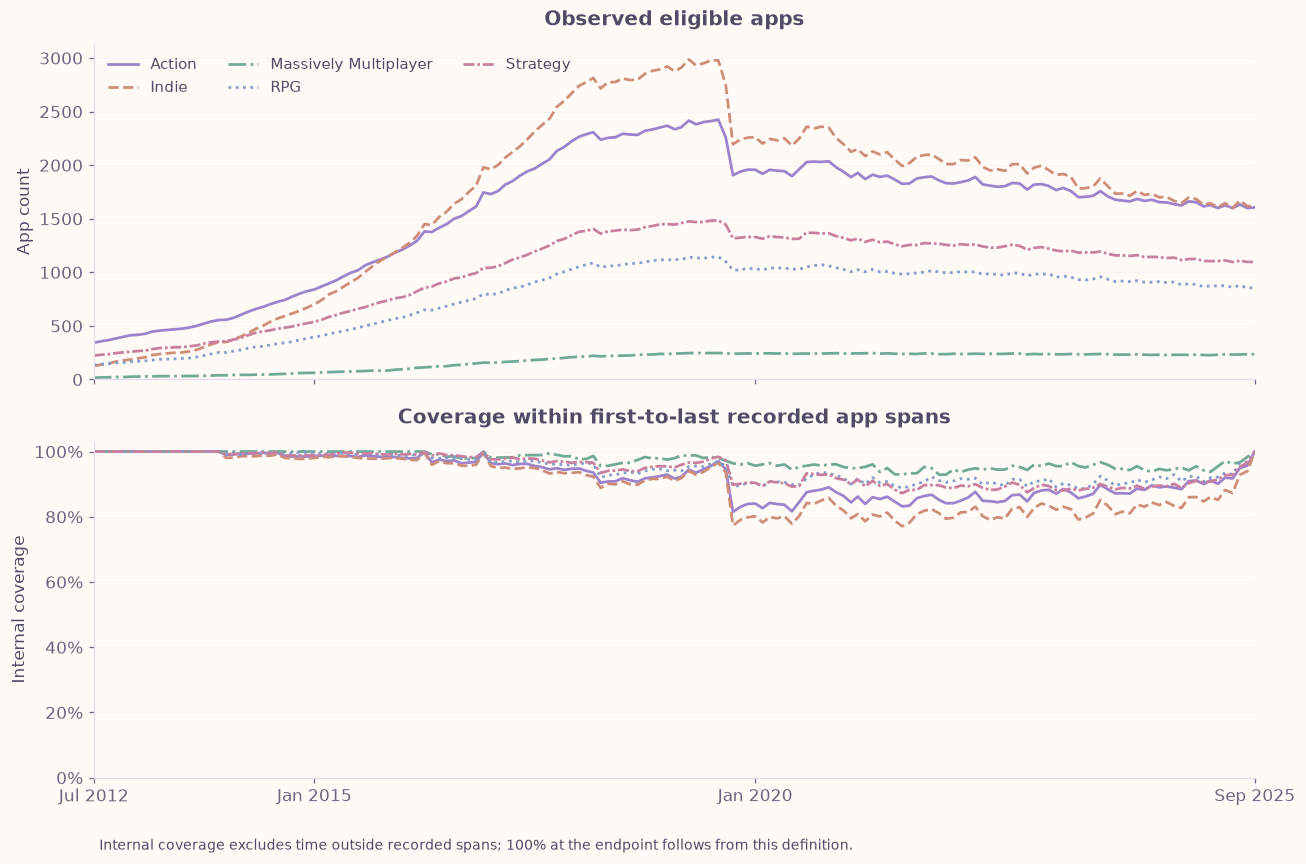

In [6]:
figure = plot_coverage(monthly)
figure.savefig(figure_folder / "category_coverage.png", dpi=150, bbox_inches="tight")
figure


In [7]:
lowest_coverage = monthly.loc[
    monthly.groupby("category")["coverage_rate"].idxmin(),
    ["category", "month", "observed_apps", "expected_apps",
     "internal_missing_apps", "coverage_rate"],
].copy()
lowest_coverage["coverage_rate"] = (lowest_coverage["coverage_rate"] * 100).round(2)
present(lowest_coverage.rename(columns={
    "category": "Category", "month": "Lowest coverage month",
    "observed_apps": "Observed apps", "expected_apps": "Expected apps",
    "internal_missing_apps": "Missing app observations",
    "coverage_rate": "Internal coverage percent",
}), 'Compare app counts with internal coverage')


,Category,Lowest coverage month,Observed apps,Expected apps,Missing app observations,Internal coverage percent
Group,,,,,,
87,Action,Oct 2019,"1,906","2,338",432,81.52%
269,Indie,Sep 2021,"1,992","2,585",593,77.06%
433,Massively Multiplayer,Feb 2022,236,254,18,92.91%
612,RPG,Oct 2023,928,"1,047",119,88.63%
746,Strategy,Sep 2021,"1,243","1,425",182,87.23%


The lowest internal coverage is **77.06%** for Indie in September 2021, with **593** expected app observations missing that month. These counts concern label-specific observations and cannot be added across labels as unique missing apps.

Coverage reaches 100% at the endpoint because a recorded span extends there only when the app has an endpoint observation. Games that disappeared earlier remain outside that denominator, so endpoint completeness leaves sample stability and market representation unresolved.

Observed app counts also drop sharply in October 2019, falling by **353** for Action and **554** for Indie from the preceding month. The shared timing warrants review of observation patterns before choosing a training window, with the cause unresolved in the available source.


## 4. Reconcile the year over year change

The comparison separates the difference between September 2024 and September 2025 into changes among apps observed in both months, contributions present only in the latest month, and contributions present only in the comparison month.

The components sum to the change in observed category totals. An app appearing in one month alone is a difference in recorded presence, with release dates, closures, and causes of missing records remaining outside the evidence. Unobserved app activity stays missing in the app-level comparison; the accounting records only its contribution to each observed total.


In [8]:
bridge_view = bridge.pivot(
    index="category", columns="component", values="activity_change"
)
bridge_view["Total observed change"] = (
    latest_summary.set_index("category")["avg_players"]
    - latest_summary.set_index("category")["comparison_activity"]
)
present(bridge_view.round(2), 'Reconcile the year over year change')


component,Observed in both months,Observed only in comparison month,Observed only in latest month,Total observed change
category,,,,
Action,"85,865.87","-1,070.41","2,427.65","87,223.11"
Indie,"-39,791.38","-1,463.91","3,904.17","-37,351.12"
Massively Multiplayer,"-56,856.83",-21.16,29.73,"-56,848.26"
RPG,"-24,228.50",-305.45,"1,039.71","-23,494.24"
Strategy,"-67,112.91",-372.60,608.57,"-66,876.94"


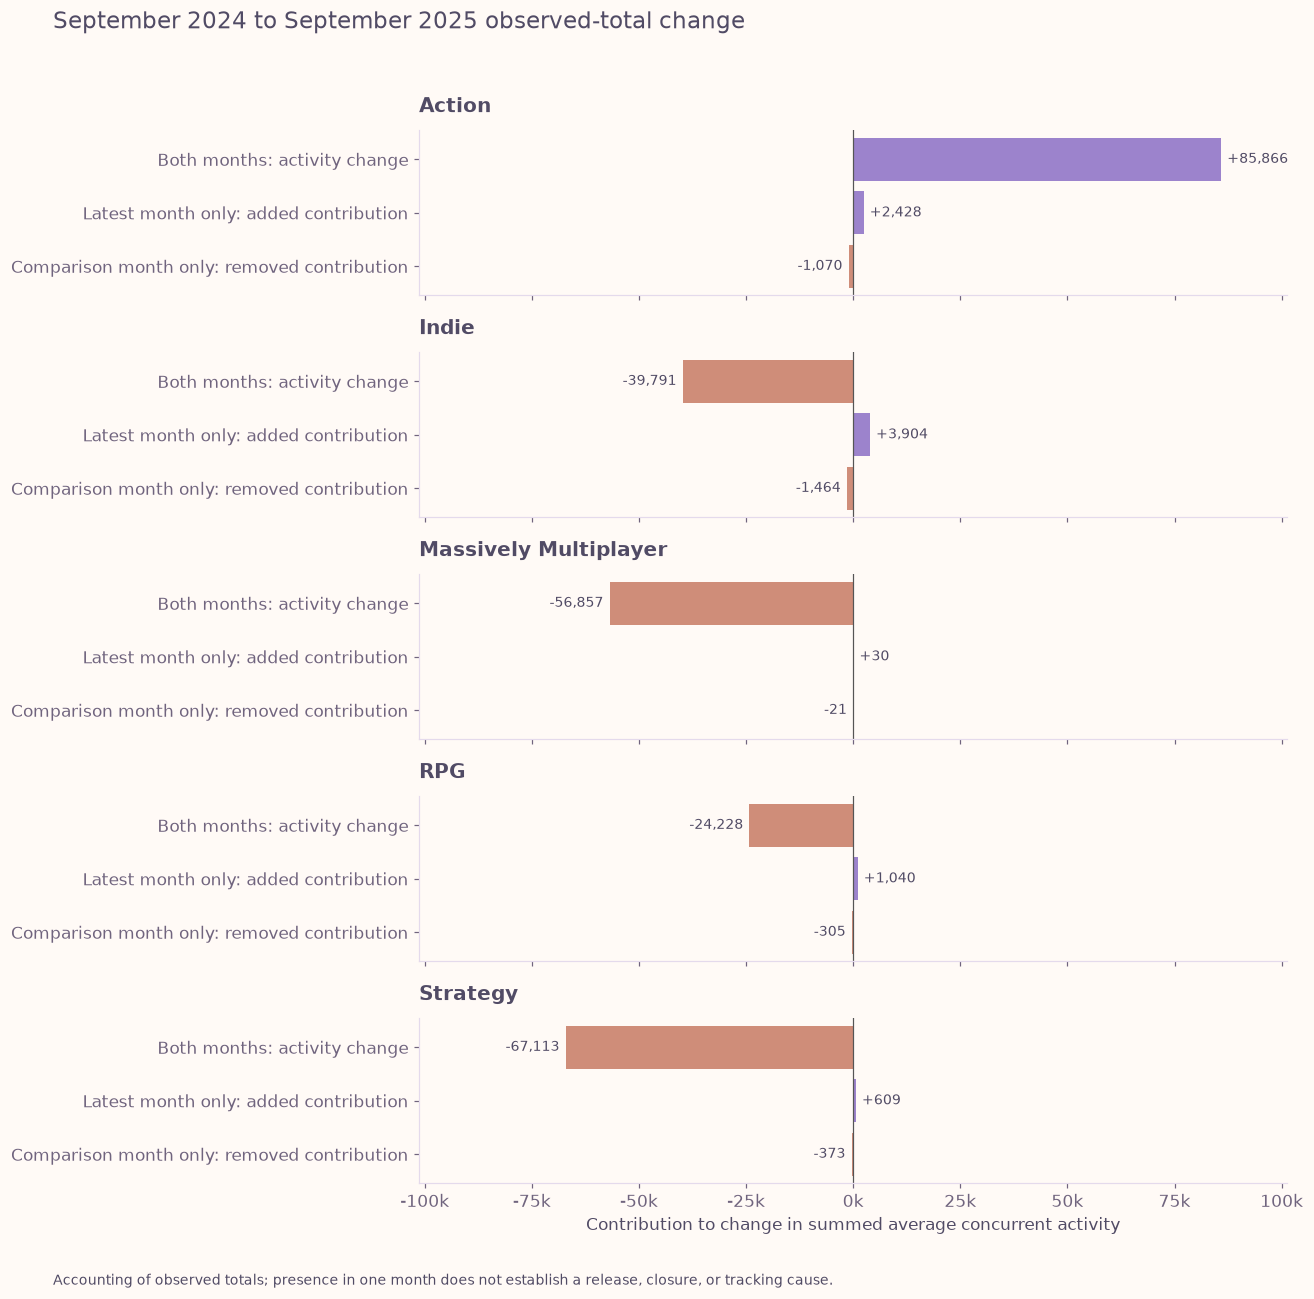

In [9]:
figure = plot_bridge(bridge)
figure.savefig(figure_folder / "category_change_components.png", dpi=150, bbox_inches="tight")
figure


Changes among apps observed in both months account for most of the measured movement in each label. For Action, the total increases by **87,223.11**, including **85,865.87** from apps observed in both months; for Strategy, the decline of **66,876.94** includes **67,112.91** of decline among those shared apps.

This narrows the arithmetic explanation for these two dates, while causes and changes during the intervening months need further evidence. The app-level export preserves missing values and identifies the records behind each component.


## Interpretation

![Checkpoint 3 — findings, interpretation and the next decision](assets/pixel_theme/checkpoint_03.svg)

The descriptive results establish category size, latest-month concentration, internal coverage, and a reconciled same-month comparison. They show why the category histories should be examined alongside their component games and changing observed samples.

Before modelling at this stage, a more recent player snapshot was needed and a justified decision about the historical training window and missingness. The following baseline evaluation used the historical scope described here; this exploratory notebook did not test forecast performance.

Recorded evidence: [exploration data](../reports/exploration_monthly.csv).
